Compare two eCMR models fitted to the same observations from the war-photo-recall experiment. Load the saved results, establish their common comparison basis, calculate AIC and save a comparison table.

## Parameters and setup

The tagged **parameters** cell contains the defaults for one run. Edit them here, or supply replacements through Quarto or Papermill. The following cell imports the tools and prepares paths from the resulting values.

Give independent jobs different `output_dir` values to keep their results separate. The discussion and saved results below describe the default example.

In [1]:
#| code-summary: "Set the parameters for this run"

fit_paths = {
    "Source-only eCMR": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "Broader eCMR": "data/fits/Dupertuys2026_eCMR_broad.json",
}
output_dir = "results/model_comparison"


In [ ]:
#| code-summary: "Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "3f0607f5cbbc56afab915577a15ede81e1398c12"
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
    ])
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(fit_paths.values(), revision=revision)


In [2]:
#| code-summary: "Import packages"

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 120})

# Resolve paths and derived settings after parameter overrides.
fit_paths = {label: Path(path) for label, path in fit_paths.items()}
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

## Establish what is being compared

Both saved records pool all three list conditions, exclude termination events from likelihood,
and use the same no-stop policy. Both have ten free parameters. The source-only model fixes
`phi_emot_modulates_temporal` to 0; the broader model fixes it to 1, allowing the emotional
modulation also to act on temporal context. The remaining fixed settings match.

These are complete historical fit records from the ECMR3 project, retained with their metadata.
They are not the short two-parameter CMR demonstration used in the preceding notebooks. Their
reported objectives are compared as recorded; this notebook does not rerun or revise those fits.

In [3]:
#| code-summary: "Read the fits and check their comparison basis"

records = {name: json.loads(path.read_text()) for name, path in fit_paths.items()}
comparison_basis = []
for name, record in records.items():
    if record["fits"]["subject"] != [-1] or len(record["fitness"]) != 1:
        raise ValueError(f"{name} is not the expected single pooled fit.")
    comparison_basis.append({
        "Model": name, "Data": record["data_tag"], "Selection": record["trial_query"],
        "Likelihood": record["loss_function"],
        "Stopping policy": record["components"]["termination_policy_create_fn"],
    })
basis = pd.DataFrame(comparison_basis)
if any(basis[column].nunique() != 1 for column in basis.columns if column != "Model"):
    raise ValueError("These fits do not record a common data selection, likelihood and stopping rule.")
display(basis[["Model", "Data", "Selection"]])
print("Common objective:", basis["Likelihood"].iloc[0])
print("Common stopping policy:", basis["Stopping policy"].iloc[0])

,Model,Data,Selection
0,Source-only eCMR,Dupertuys2026,data['list_type'] >= 1
1,Broader eCMR,Dupertuys2026,data['list_type'] >= 1


Common objective: jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodFnGenerator
Common stopping policy: jaxcmr.components.termination.NoStopTermination


## Calculate the comparison

For each pooled model, **AIC = 2 × free-parameter count + 2 × negative log likelihood**.
Lower values are preferred under this criterion. A parameter fixed before fitting is not counted
as free. Here the parameter counts are equal, so the AIC difference is twice the likelihood-score
difference. The comparison uses one pooled result per model, not 123 independently fitted estimates.

,Model,Free parameters,Negative log likelihood,AIC,Delta AIC
0,Broader eCMR,10,7170.727,14361.453,0.000
1,Source-only eCMR,10,7174.993,14369.985,8.532


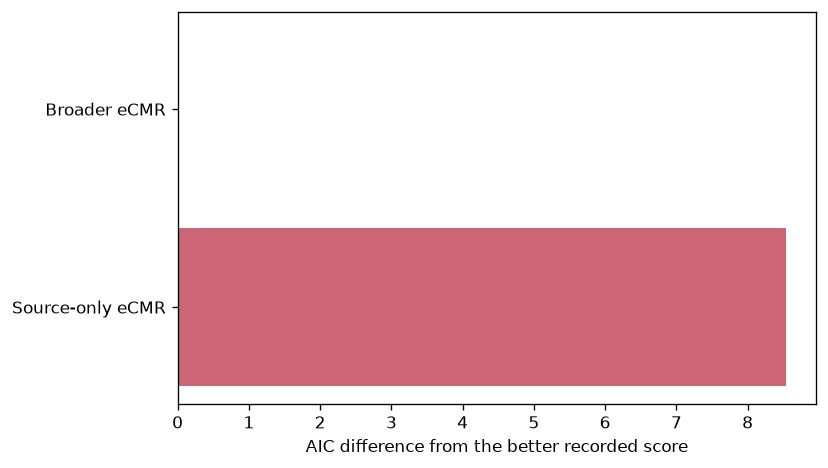

In [4]:
#| code-summary: "Calculate AIC and save the comparison"

rows = []
for name, record in records.items():
    k = len(record["free"])
    nll = float(record["fitness"][0])
    rows.append({"Model": name, "Free parameters": k, "Negative log likelihood": nll,
                 "AIC": 2 * k + 2 * nll})
comparison = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
comparison["Delta AIC"] = comparison["AIC"] - comparison["AIC"].min()
comparison.to_csv(output_dir / "pooled_model_comparison.csv", index=False)
display(comparison.round(3))
fig, ax = plt.subplots()
ax.barh(comparison["Model"], comparison["Delta AIC"], color=["#4477AA", "#CC6677"])
ax.set_xlabel("AIC difference from the better recorded score")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(output_dir / "delta_aic.png", dpi=160)
plt.show()

## Interpret and use your own fits

The broader model has the lower recorded score: its negative log likelihood is about 7170.73,
versus 7174.99 for source-only eCMR. With ten free parameters in each fit, the AIC difference is
about 8.53. The table compares these recorded solutions under a shared objective. Optimization quality,
parameter uncertainty and alternatives outside this pair remain separate questions. A lower AIC
in this example is not a conclusive theoretical result.

For another comparison, supply fits to the same observations with compatible likelihood and
stopping assumptions. Explain the model difference and count its fitted parameters correctly.
Do not turn pooled results into participant-level t-tests, winner proportions or confidence intervals.
This example uses AIC; it does not silently choose an observation count for AICc or pool unrelated studies.

The CSV table and figure are saved in `results/model_comparison/`.